In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from IPython.display import display

sns.set_theme(style="whitegrid")

uploaded = files.upload()

Saving Afficionado Coffee Roasters.xlsx - Transactions.csv to Afficionado Coffee Roasters.xlsx - Transactions.csv


In [39]:

file_name = next(iter(uploaded.keys()))

if file_name.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(file_name, sheet_name="Transactions")
else:
    df = pd.read_csv(file_name)

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()


Dataset shape: (149116, 11)

Column names:
['transaction_id', 'year', 'transaction_time', 'transaction_qty', 'store_id', 'store_location', 'product_id', 'unit_price', 'product_category', 'product_type', 'product_detail']

First 5 rows:


,transaction_id,year,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2025,7:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2025,7:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2025,7:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2025,7:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2025,7:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149116 entries, 0 to 149115
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   transaction_id    149116 non-null  int64  
 1   year              149116 non-null  int64  
 2   transaction_time  149116 non-null  object 
 3   transaction_qty   149116 non-null  int64  
 4   store_id          149116 non-null  int64  
 5   store_location    149116 non-null  object 
 6   product_id        149116 non-null  int64  
 7   unit_price        149116 non-null  float64
 8   product_category  149116 non-null  object 
 9   product_type      149116 non-null  object 
 10  product_detail    149116 non-null  object 
dtypes: float64(1), int64(5), object(5)
memory usage: 12.5+ MB


In [40]:
print("Dataset dimensions:", df.shape)

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Count"))

print("\nExact duplicate rows:", df.duplicated().sum())

print(
    "Duplicate transaction IDs:",
    df["transaction_id"].duplicated().sum()
)

print("\nYear distribution:")
display(df["year"].value_counts(dropna=False).sort_index())

print("\nNumeric summary:")
display(df.describe())

print("\nUnique store locations:")
display(df["store_location"].value_counts())

print("\nInvalid quantities:", (df["transaction_qty"] <= 0).sum())
print("\nInvalid prices:", (df["unit_price"] <= 0).sum())

Dataset dimensions: (149116, 11)

Missing values:


,Missing Count
transaction_id,0
year,0
transaction_time,0
transaction_qty,0
store_id,0
store_location,0
product_id,0
unit_price,0
product_category,0
product_type,0



Exact duplicate rows: 0
Duplicate transaction IDs: 0

Year distribution:


,count
year,
2025,149116



Numeric summary:


,transaction_id,year,transaction_qty,store_id,product_id,unit_price
count,149116.000000,149116.0,149116.000000,149116.000000,149116.000000,149116.000000
mean,74737.371872,2025.0,1.438276,5.342063,47.918607,3.382219
std,43153.600016,0.0,0.542509,2.074241,17.930020,2.658723
min,1.000000,2025.0,1.000000,3.000000,1.000000,0.800000
25%,37335.750000,2025.0,1.000000,3.000000,33.000000,2.500000
50%,74727.500000,2025.0,1.000000,5.000000,47.000000,3.000000
75%,112094.250000,2025.0,2.000000,8.000000,60.000000,3.750000
max,149456.000000,2025.0,8.000000,8.000000,87.000000,45.000000



Unique store locations:


,count
store_location,
Hell's Kitchen,50735
Astoria,50599
Lower Manhattan,47782



Invalid quantities: 0

Invalid prices: 0


In [41]:
# Keep the original data unchanged
df_clean = df.copy()

# Convert columns to the correct data types
df_clean["transaction_id"] = pd.to_numeric(
    df_clean["transaction_id"], errors="coerce"
)
df_clean["year"] = pd.to_numeric(
    df_clean["year"], errors="coerce"
)
df_clean["transaction_qty"] = pd.to_numeric(
    df_clean["transaction_qty"], errors="coerce"
)
df_clean["unit_price"] = pd.to_numeric(
    df_clean["unit_price"], errors="coerce"
)

# Convert transaction time to a consistent format
df_clean["transaction_time"] = pd.to_datetime(
    df_clean["transaction_time"].astype(str),
    format="%H:%M:%S",
    errors="coerce"
)

# Check for invalid values
print("Invalid times:", df_clean["transaction_time"].isna().sum())
print("Missing values after conversion:")
display(df_clean.isnull().sum())

# Remove only invalid records, if any
df_clean = df_clean.dropna(
    subset=[
        "transaction_id",
        "year",
        "transaction_time",
        "transaction_qty",
        "unit_price"
    ]
).copy()

# Retain valid, positive quantities and prices
df_clean = df_clean[
    (df_clean["transaction_qty"] > 0) &
    (df_clean["unit_price"] > 0)
].copy()

print("Cleaned dataset shape:", df_clean.shape)


Invalid times: 0
Missing values after conversion:


,0
transaction_id,0
year,0
transaction_time,0
transaction_qty,0
store_id,0
store_location,0
product_id,0
unit_price,0
product_category,0
product_type,0


Cleaned dataset shape: (149116, 11)


In [42]:
# Revenue for each transaction record
df_clean["revenue"] = (
    df_clean["transaction_qty"] * df_clean["unit_price"]
)

# Temporal features
df_clean["hour"] = df_clean["transaction_time"].dt.hour

df_clean["hour_label"] = df_clean["hour"].apply(
    lambda h: f"{h:02d}:00"
)

def get_time_bucket(hour):
    if 6 <= hour <= 11:
        return "Morning"
    elif 12 <= hour <= 16:
        return "Afternoon"
    elif 17 <= hour <= 21:
        return "Evening"
    else:
        return "Late hours"

df_clean["time_bucket"] = df_clean["hour"].apply(
    get_time_bucket
)

display(
    df_clean[
        [
            "transaction_id",
            "transaction_time",
            "hour",
            "time_bucket",
            "transaction_qty",
            "unit_price",
            "revenue"
        ]
    ].head(10)
)

print("Total quantity:", df_clean["transaction_qty"].sum())
print("Total revenue:", round(df_clean["revenue"].sum(), 2))
print("Transaction records:", len(df_clean))

,transaction_id,transaction_time,hour,time_bucket,transaction_qty,unit_price,revenue
0,1,1900-01-01 07:06:11,7,Morning,2,3.00,6.00
1,2,1900-01-01 07:08:56,7,Morning,2,3.10,6.20
2,3,1900-01-01 07:14:04,7,Morning,2,4.50,9.00
3,4,1900-01-01 07:20:24,7,Morning,1,2.00,2.00
4,5,1900-01-01 07:22:41,7,Morning,2,3.10,6.20
5,6,1900-01-01 07:22:41,7,Morning,1,3.00,3.00
6,7,1900-01-01 07:25:49,7,Morning,1,2.00,2.00
7,8,1900-01-01 07:33:34,7,Morning,2,2.00,4.00
8,9,1900-01-01 07:39:13,7,Morning,1,4.25,4.25
9,10,1900-01-01 07:39:34,7,Morning,2,3.50,7.00


Total quantity: 214470
Total revenue: 698812.33
Transaction records: 149116


In [43]:
total_revenue = df_clean["revenue"].sum()
total_records = len(df_clean)
total_quantity = df_clean["transaction_qty"].sum()
average_record_revenue = df_clean["revenue"].mean()

kpis = pd.DataFrame({
    "Metric": [
        "Total Revenue",
        "Transaction Records",
        "Total Quantity Sold",
        "Average Revenue per Record",
        "Number of Store Locations"
    ],
    "Value": [
        round(total_revenue, 2),
        total_records,
        total_quantity,
        round(average_record_revenue, 2),
        df_clean["store_location"].nunique()
    ]
})

display(kpis)

,Metric,Value
0,Total Revenue,698812.33
1,Transaction Records,149116.00
2,Total Quantity Sold,214470.00
3,Average Revenue per Record,4.69
4,Number of Store Locations,3.00


,hour,revenue,transaction_records,quantity_sold
0,6,21900.27,4594,6865
1,7,63526.47,13428,19449
2,8,82699.87,17654,25197
3,9,85169.53,17764,25370
4,10,88673.39,18545,26713
5,11,46319.14,9766,14035
6,12,40192.79,8708,12690
7,13,40367.45,8714,12439
8,14,41304.74,8933,12907
9,15,41733.10,8979,12923


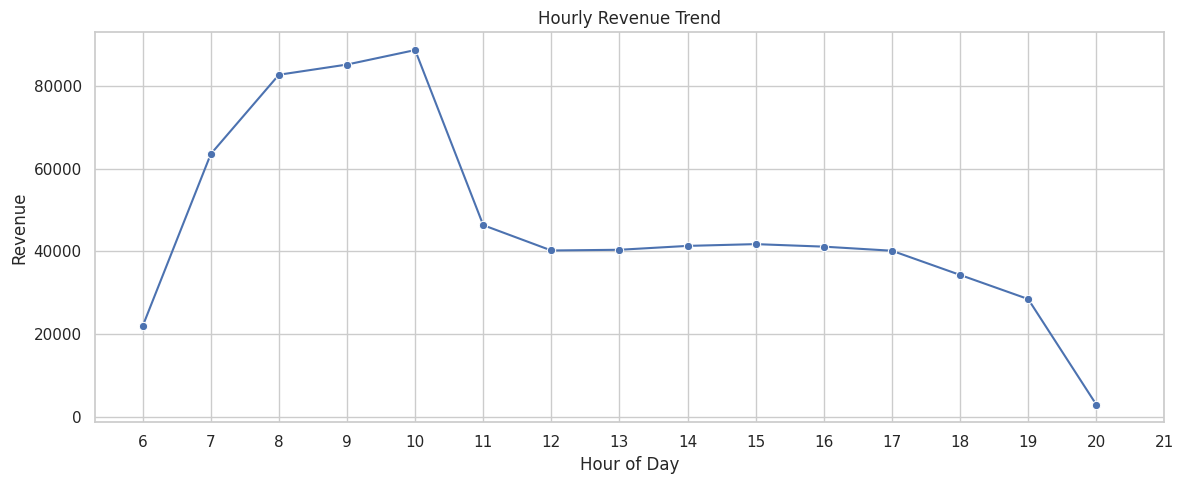

In [44]:
hourly_sales = (
    df_clean.groupby("hour")
    .agg(
        revenue=("revenue", "sum"),
        transaction_records=("transaction_id", "count"),
        quantity_sold=("transaction_qty", "sum")
    )
    .reset_index()
)

display(hourly_sales)

plt.figure(figsize=(12, 5))
sns.lineplot(
    data=hourly_sales,
    x="hour",
    y="revenue",
    marker="o"
)
plt.title("Hourly Revenue Trend")
plt.xlabel("Hour of Day")
plt.ylabel("Revenue")
plt.xticks(range(6, 22))
plt.tight_layout()
plt.show()


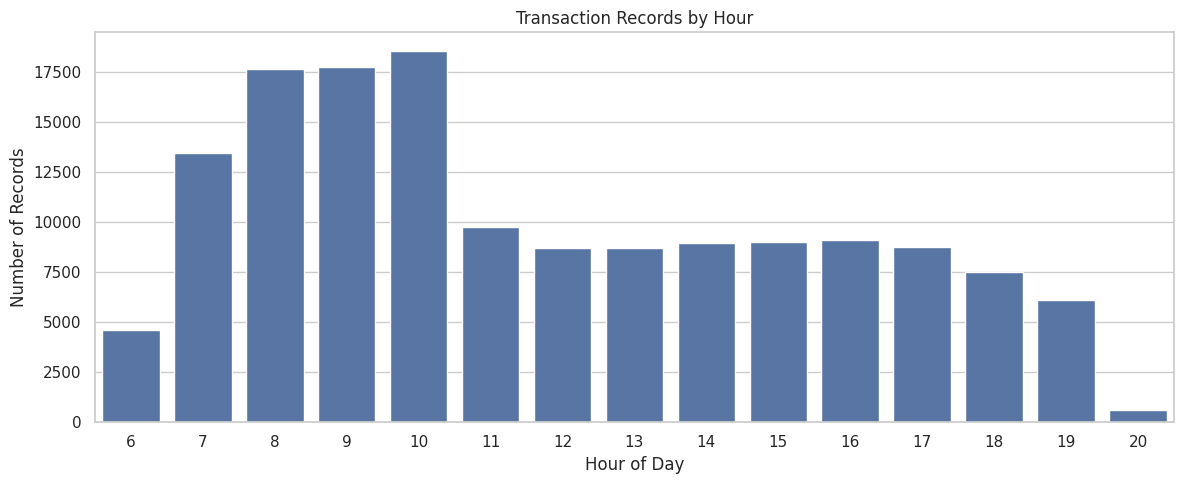

Busiest hour:


,hour,transaction_records
4,10,18545
3,9,17764
2,8,17654
1,7,13428
5,11,9766


In [45]:
hourly_counts = (
    df_clean.groupby("hour")
    .size()
    .reset_index(name="transaction_records")
)

plt.figure(figsize=(12, 5))
sns.barplot(
    data=hourly_counts,
    x="hour",
    y="transaction_records"
)
plt.title("Transaction Records by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

print("Busiest hour:")
display(
    hourly_counts.sort_values(
        "transaction_records", ascending=False
    ).head(5)
)

,store_location,revenue,transaction_records,quantity_sold
1,Hell's Kitchen,236511.17,50735,71737
0,Astoria,232243.91,50599,70991
2,Lower Manhattan,230057.25,47782,71742


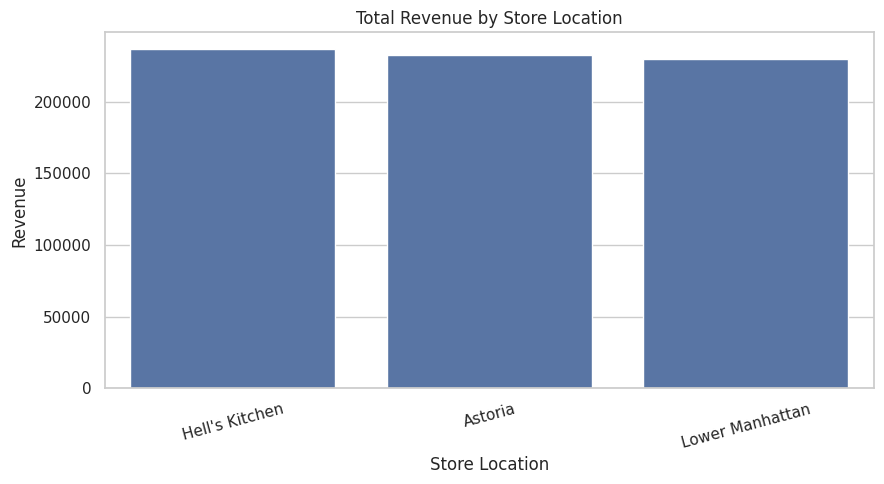

In [46]:
store_summary = (
    df_clean.groupby("store_location")
    .agg(
        revenue=("revenue", "sum"),
        transaction_records=("transaction_id", "count"),
        quantity_sold=("transaction_qty", "sum")
    )
    .reset_index()
    .sort_values("revenue", ascending=False)
)

display(store_summary)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=store_summary,
    x="store_location",
    y="revenue"
)
plt.title("Total Revenue by Store Location")
plt.xlabel("Store Location")
plt.ylabel("Revenue")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

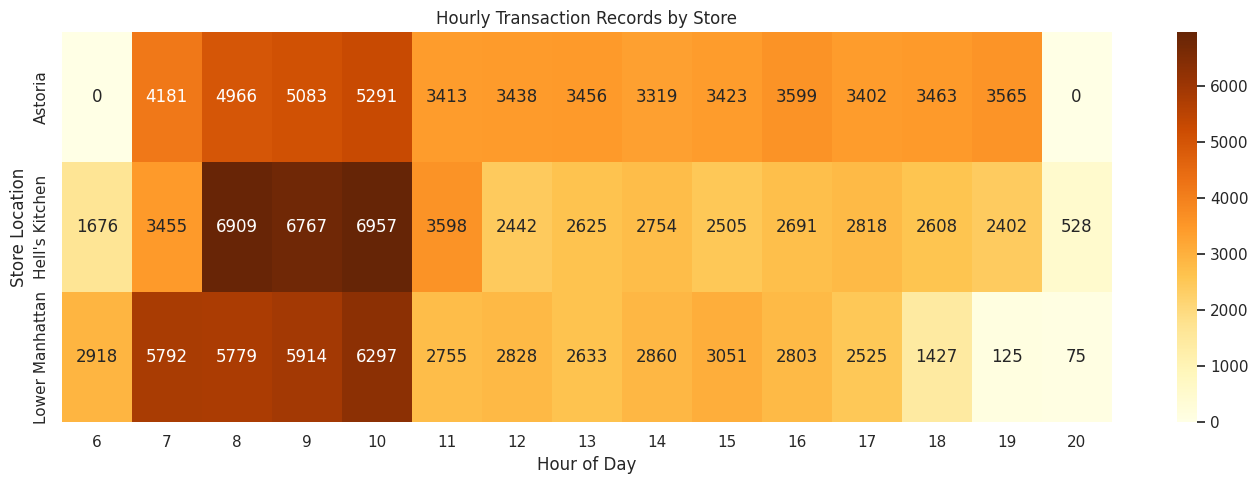

In [47]:
heatmap_data = df_clean.pivot_table(
    index="store_location",
    columns="hour",
    values="transaction_id",
    aggfunc="count",
    fill_value=0
)

plt.figure(figsize=(14, 5))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt="g",
    cmap="YlOrBr"
)
plt.title("Hourly Transaction Records by Store")
plt.xlabel("Hour of Day")
plt.ylabel("Store Location")
plt.tight_layout()
plt.show()

In [48]:
bucket_summary = (
    df_clean.groupby("time_bucket")
    .agg(
        revenue=("revenue", "sum"),
        transaction_records=("transaction_id", "count"),
        quantity_sold=("transaction_qty", "sum")
    )
    .reindex(["Morning", "Afternoon", "Evening", "Late hours"])
    .reset_index()
)

display(bucket_summary)

category_summary = (
    df_clean.groupby("product_category")
    .agg(
        revenue=("revenue", "sum"),
        quantity_sold=("transaction_qty", "sum"),
        transaction_records=("transaction_id", "count")
    )
    .sort_values("revenue", ascending=False)
    .reset_index()
)

display(category_summary)

,time_bucket,revenue,transaction_records,quantity_sold
0,Morning,388288.67,81751.0,117629.0
1,Afternoon,204720.83,44427.0,63840.0
2,Evening,105802.83,22938.0,33001.0
3,Late hours,NaN,NaN,NaN


,product_category,revenue,quantity_sold,transaction_records
0,Coffee,269952.45,89250,58416
1,Tea,196405.95,69737,45449
2,Bakery,82315.64,23214,22796
3,Drinking Chocolate,72416.00,17457,11468
4,Coffee beans,40085.25,1828,1753
5,Branded,13607.00,776,747
6,Loose Tea,11213.60,1210,1210
7,Flavours,8408.80,10511,6790
8,Packaged Chocolate,4407.64,487,487


In [49]:
df_clean.to_csv("afficionado_cleaned_data.csv", index=False)
hourly_sales.to_csv("hourly_sales_summary.csv", index=False)
store_summary.to_csv("store_summary.csv", index=False)
bucket_summary.to_csv("time_bucket_summary.csv", index=False)
category_summary.to_csv("category_summary.csv", index=False)

print("Analysis files created successfully.")

Analysis files created successfully.


In [50]:
from google.colab import files

files.download("afficionado_cleaned_data.csv")
files.download("hourly_sales_summary.csv")
files.download("store_summary.csv")
files.download("time_bucket_summary.csv")
files.download("category_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [51]:
!pip -q install streamlit plotly

In [52]:

%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from io import BytesIO

st.set_page_config(
    page_title="Afficionado Coffee | Sales Analytics",
    page_icon="☕",
    layout="wide"
)

# -------------------- Styling --------------------
st.markdown("""
<style>
    .block-container {padding-top: 1.5rem; padding-bottom: 2rem;}
    div[data-testid="stMetric"] {
        background: #f4f7f6;
        border: 1px solid #e0e8e4;
        padding: 15px;
        border-radius: 12px;
    }
</style>
""", unsafe_allow_html=True)

st.title("☕ Afficionado Coffee Roasters")
st.subheader("Sales Trend & Time-Based Performance Analysis")
st.caption(
    "Interactive sales analytics | Hourly demand | Store comparisons"
)

# -------------------- Data upload --------------------
st.sidebar.header("1. Load your data")
uploaded_file = st.sidebar.file_uploader(
    "Upload afficionado_cleaned_data.csv",
    type=["csv"]
)

if uploaded_file is None:
    st.info(
        "Upload your cleaned CSV in the sidebar to open the dashboard. "
        "Use the file exported from Colab Steps 1–8."
    )
    st.markdown("""
    **Required columns**
    - `transaction_id`
    - `transaction_qty`
    - `unit_price`
    - `store_location`
    - `transaction_time` or `hour`

    The app can calculate revenue if it is not already included.
    """)
    st.stop()

try:
    df = pd.read_csv(uploaded_file)
except Exception as exc:
    st.error(f"Could not read the CSV file: {exc}")
    st.stop()

# -------------------- Validate columns --------------------
required = [
    "transaction_qty", "unit_price", "store_location"
]
missing = [col for col in required if col not in df.columns]

if missing:
    st.error(f"Missing required columns: {', '.join(missing)}")
    st.stop()

df = df.copy()

# Numeric conversion
for col in ["transaction_qty", "unit_price", "year"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Determine hour from existing hour column or transaction_time
if "hour" in df.columns:
    df["hour"] = pd.to_numeric(df["hour"], errors="coerce")
elif "transaction_time" in df.columns:
    parsed_time = pd.to_datetime(
        df["transaction_time"].astype(str),
        errors="coerce"
    )
    df["hour"] = parsed_time.dt.hour
else:
    st.error("The CSV must contain 'hour' or 'transaction_time'.")
    st.stop()

# Revenue
if "revenue" not in df.columns:
    df["revenue"] = df["transaction_qty"] * df["unit_price"]
else:
    df["revenue"] = pd.to_numeric(
        df["revenue"], errors="coerce"
    )

# Remove invalid analytical rows
df = df.dropna(subset=[
    "transaction_qty", "unit_price", "store_location",
    "hour", "revenue"
])

df = df[
    df["transaction_qty"].gt(0)
    & df["unit_price"].gt(0)
    & df["hour"].between(0, 23)
].copy()

if df.empty:
    st.error("No valid records remain after validation.")
    st.stop()

df["hour"] = df["hour"].astype(int)
df["store_location"] = df["store_location"].astype(str)

# Create labels for chart axes
df["hour_label"] = df["hour"].map(
    lambda h: f"{h:02d}:00"
)

# -------------------- Sidebar filters --------------------
st.sidebar.header("2. Filter the analysis")

stores = sorted(df["store_location"].unique().tolist())
selected_stores = st.sidebar.multiselect(
    "Store location",
    options=stores,
    default=stores
)

if not selected_stores:
    st.warning("Select at least one store location.")
    st.stop()

hour_min = int(df["hour"].min())
hour_max = int(df["hour"].max())

hour_range = st.sidebar.slider(
    "Hour range",
    min_value=hour_min,
    max_value=hour_max,
    value=(hour_min, hour_max),
    format="%d:00"
)

metric_label = st.sidebar.radio(
    "Chart metric",
    ["Revenue", "Quantity sold", "Transaction records"],
    horizontal=False
)

metric_map = {
    "Revenue": "revenue",
    "Quantity sold": "transaction_qty",
    "Transaction records": "transaction_id"
}
metric_col = metric_map[metric_label]

filtered = df[
    df["store_location"].isin(selected_stores)
    & df["hour"].between(hour_range[0], hour_range[1])
].copy()

if filtered.empty:
    st.warning("No records match the selected filters.")
    st.stop()

# -------------------- Executive overview --------------------
total_revenue = filtered["revenue"].sum()
total_quantity = filtered["transaction_qty"].sum()
record_count = len(filtered)
average_revenue = total_revenue / record_count if record_count else 0

st.header("Executive Overview")

c1, c2, c3, c4 = st.columns(4)
c1.metric("Total Revenue", f"{total_revenue:,.2f}")
c2.metric("Transaction Records", f"{record_count:,}")
c3.metric("Quantity Sold", f"{total_quantity:,.0f}")
c4.metric("Average Revenue / Record", f"{average_revenue:,.2f}")

st.caption(
    "Revenue is quantity multiplied by unit price. "
    "Transaction records are row counts, not unique customers."
)

# -------------------- Hourly performance --------------------
st.header("Hourly Demand Analysis")

hourly = (
    filtered.groupby("hour", as_index=False)
    .agg(
        revenue=("revenue", "sum"),
        quantity_sold=("transaction_qty", "sum"),
        transaction_records=("transaction_qty", "size")
    )
    .sort_values("hour")
)

if metric_label == "Transaction records":
    y_col = "transaction_records"
else:
    y_col = metric_col

fig_hour = px.bar(
    hourly,
    x="hour",
    y=y_col,
    title=f"{metric_label} by Hour",
    labels={
        "hour": "Hour of Day",
        y_col: metric_label
    },
    text_auto=".3s"
)
fig_hour.update_xaxes(
    tickmode="linear", dtick=1, tickformat="02d"
)
fig_hour.update_layout(
    template="plotly_white",
    hovermode="x unified"
)
st.plotly_chart(fig_hour, use_container_width=True)

fig_line = px.line(
    hourly,
    x="hour",
    y=y_col,
    markers=True,
    title=f"Hourly {metric_label} Trend",
    labels={"hour": "Hour of Day", y_col: metric_label}
)
fig_line.update_xaxes(tickmode="linear", dtick=1)
fig_line.update_layout(template="plotly_white")
st.plotly_chart(fig_line, use_container_width=True)

# Report the peak hour within the selected filters
peak_row = hourly.loc[hourly[y_col].idxmax()]
st.success(
    f"Peak hour in the current selection: "
    f"{int(peak_row['hour']):02d}:00 "
    f"({peak_row[y_col]:,.2f} {metric_label.lower()})."
)

# -------------------- Store comparison --------------------
st.header("Store Location Comparison")

store_summary = (
    filtered.groupby("store_location", as_index=False)
    .agg(
        revenue=("revenue", "sum"),
        quantity_sold=("transaction_qty", "sum"),
        transaction_records=("transaction_qty", "size")
    )
)

st.dataframe(
    store_summary.sort_values("revenue", ascending=False),
    use_container_width=True,
    hide_index=True
)

fig_store = px.bar(
    store_summary,
    x="store_location",
    y=y_col,
    color="store_location",
    title=f"{metric_label} by Store",
    labels={
        "store_location": "Store Location",
        y_col: metric_label
    }
)
fig_store.update_layout(
    template="plotly_white",
    showlegend=False
)
st.plotly_chart(fig_store, use_container_width=True)

# -------------------- Store-hour heatmap --------------------
st.header("Store-by-Hour Heatmap")

heatmap_source = filtered.copy()

heatmap = heatmap_source.pivot_table(
    index="store_location",
    columns="hour",
    values="transaction_id" if metric_label == "Transaction records"
          and "transaction_id" in heatmap_source.columns
          else ("revenue" if metric_label == "Revenue"
                else "transaction_qty"),
    aggfunc="count" if metric_label == "Transaction records"
            else "sum",
    fill_value=0
)

# Ensure heatmap metric is consistent with selected metric
if metric_label == "Transaction records":
    heatmap = heatmap_source.pivot_table(
        index="store_location",
        columns="hour",
        values="transaction_qty",
        aggfunc="size",
        fill_value=0
    )
elif metric_label == "Revenue":
    heatmap = heatmap_source.pivot_table(
        index="store_location",
        columns="hour",
        values="revenue",
        aggfunc="sum",
        fill_value=0
    )
else:
    heatmap = heatmap_source.pivot_table(
        index="store_location",
        columns="hour",
        values="transaction_qty",
        aggfunc="sum",
        fill_value=0
    )

heatmap = heatmap.reindex(
    columns=list(range(hour_range[0], hour_range[1] + 1)),
    fill_value=0
)

fig_heat = px.imshow(
    heatmap,
    aspect="auto",
    color_continuous_scale="YlOrBr",
    labels={
        "x": "Hour of Day",
        "y": "Store Location",
        "color": metric_label
    },
    title=f"{metric_label} by Store and Hour"
)
fig_heat.update_xaxes(
    tickmode="array",
    tickvals=list(range(len(heatmap.columns))),
    ticktext=[f"{int(h):02d}:00" for h in heatmap.columns]
)
st.plotly_chart(fig_heat, use_container_width=True)

# -------------------- Time buckets --------------------
st.header("Time-of-Day Performance")

def time_bucket(hour):
    if 6 <= hour <= 11:
        return "Morning"
    elif 12 <= hour <= 16:
        return "Afternoon"
    elif 17 <= hour <= 21:
        return "Evening"
    return "Late hours"

filtered["time_bucket"] = filtered["hour"].apply(time_bucket)

bucket_summary = (
    filtered.groupby("time_bucket", as_index=False)
    .agg(
        revenue=("revenue", "sum"),
        quantity_sold=("transaction_qty", "sum"),
        transaction_records=("transaction_qty", "size")
    )
)

bucket_order = ["Morning", "Afternoon", "Evening", "Late hours"]
bucket_summary["time_bucket"] = pd.Categorical(
    bucket_summary["time_bucket"],
    categories=bucket_order,
    ordered=True
)
bucket_summary = bucket_summary.sort_values("time_bucket")

st.dataframe(bucket_summary, use_container_width=True, hide_index=True)

fig_bucket = px.bar(
    bucket_summary,
    x="time_bucket",
    y=y_col,
    title=f"{metric_label} by Time Bucket",
    labels={"time_bucket": "Time of Day", y_col: metric_label}
)
fig_bucket.update_layout(template="plotly_white")
st.plotly_chart(fig_bucket, use_container_width=True)

# -------------------- Product category --------------------
if "product_category" in filtered.columns:
    st.header("Product Category Performance")

    product_summary = (
        filtered.groupby("product_category", as_index=False)
        .agg(
            revenue=("revenue", "sum"),
            quantity_sold=("transaction_qty", "sum"),
            transaction_records=("transaction_qty", "size")
        )
        .sort_values("revenue", ascending=False)
    )

    st.dataframe(
        product_summary,
        use_container_width=True,
        hide_index=True
    )

    fig_product = px.bar(
        product_summary.head(10),
        x="product_category",
        y=y_col,
        title=f"Top Product Categories by {metric_label}",
        labels={
            "product_category": "Product Category",
            y_col: metric_label
        }
    )
    fig_product.update_layout(
        template="plotly_white",
        xaxis_tickangle=-30
    )
    st.plotly_chart(fig_product, use_container_width=True)

# -------------------- Download filtered data --------------------
st.header("Export Results")

csv_bytes = filtered.to_csv(index=False).encode("utf-8")

st.download_button(
    label="Download filtered transactions (CSV)",
    data=csv_bytes,
    file_name="afficionado_filtered_transactions.csv",
    mime="text/csv"
)

st.caption(
    "Date limitation: the source dataset has no transaction_date. "
    "Daily trends, weekday comparisons and weekend analysis are "
    "not displayed. No dates have been fabricated."
)

st.caption("Afficionado Coffee Roasters | Sales Analytics Project")


Overwriting app.py


In [75]:

from pathlib import Path

app_path = Path("/content/app.py")
code = app_path.read_text()

old_css = '''    div[data-testid="stMetric"] {
        background: #f4f7f6;
        border: 1px solid #e0e8e4;
        padding: 15px;
        border-radius: 12px;
    }'''

new_css = '''    div[data-testid="stMetric"] {
        background: #0a0a0a;
        border: 1px solid #e0e8e4;
        padding: 15px;
        border-radius: 12px;
    }

    div[data-testid="stMetric"] label,
    div[data-testid="stMetric"] label *,
    div[data-testid="stMetricValue"],
    div[data-testid="stMetricValue"] *,
    div[data-testid="stMetricDelta"] {
        color: #1f2937 !important;
    }'''

if "color: #1f2937 !important;" in code:
    print("KPI text color correction is already present.")
elif old_css in code:
    app_path.write_text(code.replace(old_css, new_css, 1))
    print("Updated app.py successfully!")
else:
    print("Could not find the expected CSS. No changes made.")


KPI text color correction is already present.


In [61]:

from pathlib import Path

app_path = Path("/content/app.py")
code = app_path.read_text()

old_code = '''if metric_label == "Transaction records":
    y_col = "transaction_records"
else:
    y_col = metric_col'''

new_code = '''if metric_label == "Revenue":
    y_col = "revenue"
elif metric_label == "Quantity sold":
    y_col = "quantity_sold"
else:
    y_col = "transaction_records"'''

if old_code in code:
    code = code.replace(old_code, new_code, 1)
    app_path.write_text(code)
    print("Updated app.py successfully.")
elif new_code in code:
    print("The correction is already present in app.py.")
else:
    print("Could not find the exact code section. Do not change anything yet.")


Updated app.py successfully.


In [62]:
!grep -n -A 6 'y_col = "transaction_records"' /content/app.py

209:    y_col = "transaction_records"
210-
211-fig_hour = px.bar(
212-    hourly,
213-    x="hour",
214-    y=y_col,
215-    title=f"{metric_label} by Hour",


In [80]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [81]:
!cat /content/streamlit.log



2026-10-15 22:52:08.150 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.117.79.221:8501



In [82]:
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏
changed 22 packages in 1s
⠏
⠏3 packages are looking for funding
⠏  run `npm fund` for details
⠏

In [83]:
!lt --port 8501

your url is: https://calm-sides-retire.loca.lt
^C
